# Practical 6 (Mini-Project) — Naive vs Rabin-Karp String Matching

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)  
**Mini-project option:** C — Naive string matching and Rabin-Karp

---

## 1. Aim

Implement the **Naive string-matching algorithm** and the **Rabin-Karp
algorithm**, run both on the same inputs, and observe the difference in their
working and performance.

## 2. Problem statement

Given a text $T$ of length $n$ and a pattern $P$ of length $m$, report every
starting index $i$ such that

$$T[i],T[i+1],\dots,T[i+m-1] = P[0],P[1],\dots,P[m-1].$$

Implement:

1. **Naive search** — compare the pattern with every window.
2. **Rabin-Karp** — compare hashes of the pattern and each window, and verify
   only when the hashes match.

Compare the number of operations and the running time on random and
worst-case inputs.

## 3. Objectives

- Understand the sliding-window model of string matching.
- Understand how a rolling hash turns a window comparison into $O(1)$ work.
- Observe the effect of hash collisions and why verification is necessary.
- Compare average-case and worst-case behaviour experimentally.

## 4. Theory

### 4.1 Naive algorithm

For every start position $i=0,\dots,n-m$:

```text
j = 0
while j < m and T[i+j] == P[j]
    j = j + 1
if j == m
    report i
```

- **Best case:** the first character mismatches at every window: $O(n)$.
- **Worst case:** every window matches for $m-1$ characters and then fails:
  $O(nm)$.
- **Space:** $O(1)$ extra.

### 4.2 Rabin-Karp

Treat a string as a base-$b$ number. For a window $T[i..i+m-1]$:

$$H(i)=\left(\sum_{k=0}^{m-1} T[i+k]\cdot b^{m-1-k}\right)\bmod q.$$

The hash of the next window can be computed from the current one in $O(1)$:

$$H(i+1)=\bigl((H(i)-T[i]\cdot b^{m-1})\cdot b+T[i+m]\bigr)\bmod q.$$

Algorithm:

1. Compute the pattern hash and the first window hash.
2. Slide the window one character at a time, updating the hash in $O(1)$.
3. If the hashes match, **verify the window character by character**. A hash
   match is only a candidate; different strings can collide modulo $q$.

- **Expected time:** $O(n+m)$ if the hash behaves randomly and collisions are
  rare.
- **Worst case:** $O(nm)$ if every window has the same hash (for example,
  repetitive text with a poorly chosen modulus), because every candidate is
  verified.
- **Space:** $O(1)$ extra.

### 4.3 Why hashing helps

The naive algorithm compares up to $m$ characters per window. Rabin-Karp
compares one integer per window; only windows whose hash matches are checked
character by character. On random text, very few windows pass the hash test,
so the total work is close to $O(n+m)$.

In [1]:
import random
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def naive_search(text: str, pattern: str):
    """Return (match_positions, character_comparisons)."""
    n, m = len(text), len(pattern)
    if m == 0:
        return [], 0
    if m > n:
        return [], 0

    matches = []
    comparisons = 0
    for start in range(n - m + 1):
        offset = 0
        while offset < m:
            comparisons += 1
            if text[start + offset] != pattern[offset]:
                break
            offset += 1
        if offset == m:
            matches.append(start)
    return matches, comparisons


def rabin_karp(
    text: str,
    pattern: str,
    base: int = 256,
    modulus: int = 1_000_000_007,
):
    """Return (match_positions, hash_comparisons, character_verifications)."""
    n, m = len(text), len(pattern)
    if m == 0:
        return [], 0, 0
    if m > n:
        return [], 0, 0

    # b^(m-1) mod q, used to remove the outgoing character.
    high_power = pow(base, m - 1, modulus)

    pattern_hash = 0
    window_hash = 0
    for index in range(m):
        pattern_hash = (pattern_hash * base + ord(pattern[index])) % modulus
        window_hash = (window_hash * base + ord(text[index])) % modulus

    matches = []
    hash_comparisons = 0
    character_verifications = 0

    for start in range(n - m + 1):
        hash_comparisons += 1

        if window_hash == pattern_hash:
            # Verify to rule out a hash collision.
            offset = 0
            while offset < m:
                character_verifications += 1
                if text[start + offset] != pattern[offset]:
                    break
                offset += 1
            if offset == m:
                matches.append(start)

        # Roll the hash to the next window.
        if start < n - m:
            outgoing = ord(text[start])
            incoming = ord(text[start + m])
            window_hash = (
                (window_hash - outgoing * high_power) * base + incoming
            ) % modulus

    return matches, hash_comparisons, character_verifications

In [3]:
# The classic example: pattern AABA occurs at positions 0, 9 and 12.
text = "AABAACAADAABAABA"
pattern = "AABA"

naive_matches, naive_comparisons = naive_search(text, pattern)
rk_matches, rk_hashes, rk_verifications = rabin_karp(text, pattern)

print("Text              :", text)
print("Pattern           :", pattern)
print("Naive matches     :", naive_matches)
print("Rabin-Karp matches:", rk_matches)
print("Naive comparisons :", naive_comparisons)
print("RK hash checks    :", rk_hashes)
print("RK verifications  :", rk_verifications)
assert naive_matches == rk_matches == [0, 9, 12]
print("\nBoth algorithms agree ✓")

Text              : AABAACAADAABAABA
Pattern           : AABA
Naive matches     : [0, 9, 12]
Rabin-Karp matches: [0, 9, 12]
Naive comparisons : 30
RK hash checks    : 13
RK verifications  : 12

Both algorithms agree ✓


In [4]:
# Show the alignment of each match.
for position in rk_matches:
    print(" " * position + pattern)
    print(text)
    print(" " * position + "^" * len(pattern))
    print()

AABA
AABAACAADAABAABA
^^^^

         AABA
AABAACAADAABAABA
         ^^^^

            AABA
AABAACAADAABAABA
            ^^^^



### Correctness tests

The two algorithms must return exactly the same match positions on:

- a pattern at the beginning, middle and end,
- overlapping matches,
- a pattern that does not occur,
- a pattern longer than the text,
- an empty pattern.

In [5]:
test_cases = [
    ("hello world", "hello"),
    ("hello world", "world"),
    ("aaaaa", "aa"),          # overlapping matches
    ("aaaaa", "aaa"),         # more overlapping matches
    ("abcdef", "gh"),
    ("abc", "abcdef"),
    ("abc", ""),
    ("", ""),
    ("abababab", "abab"),
    ("the quick brown fox", "quick"),
]

for test_text, test_pattern in test_cases:
    naive_result, _ = naive_search(test_text, test_pattern)
    rk_result, _, _ = rabin_karp(test_text, test_pattern)
    assert naive_result == rk_result, (test_text, test_pattern, naive_result, rk_result)
    print(f"text={test_text!r:24} pattern={test_pattern!r:8} matches={naive_result}")

print("\nAll correctness tests passed ✓")

text='hello world'            pattern='hello'  matches=[0]
text='hello world'            pattern='world'  matches=[6]
text='aaaaa'                  pattern='aa'     matches=[0, 1, 2, 3]
text='aaaaa'                  pattern='aaa'    matches=[0, 1, 2]
text='abcdef'                 pattern='gh'     matches=[]
text='abc'                    pattern='abcdef' matches=[]
text='abc'                    pattern=''       matches=[]
text=''                       pattern=''       matches=[]
text='abababab'               pattern='abab'   matches=[0, 2, 4]
text='the quick brown fox'    pattern='quick'  matches=[4]

All correctness tests passed ✓


### Worst-case input for the naive algorithm

Consider a text made of $n$ copies of `A` and a pattern of $m-1$ `A`s followed
by one `B`. At every alignment the naive algorithm compares all $m$
characters, finds the mismatch at the last position, and moves one position to
the right. That gives $(n-m+1)m$ character comparisons.

Rabin-Karp computes the pattern hash once and then one hash per window. Since
the pattern hash is different from the window hashes (the pattern contains a
`B`), there is no character verification at all.

In [6]:
repetitive_text = "A" * 20_000
repetitive_pattern = "A" * 9 + "B"

naive_matches, naive_comparisons = naive_search(repetitive_text, repetitive_pattern)
rk_matches, rk_hashes, rk_verifications = rabin_karp(
    repetitive_text, repetitive_pattern
)

print("Text length       :", len(repetitive_text))
print("Pattern length    :", len(repetitive_pattern))
print("Naive matches     :", naive_matches)
print("RK matches        :", rk_matches)
print("Naive comparisons :", naive_comparisons)
print("RK hash checks    :", rk_hashes)
print("RK verifications  :", rk_verifications)
print(
    "Theoretical naive maximum:",
    (len(repetitive_text) - len(repetitive_pattern) + 1)
    * len(repetitive_pattern),
)

Text length       : 20000
Pattern length    : 10
Naive matches     : []
RK matches        : []
Naive comparisons : 199910
RK hash checks    : 19991
RK verifications  : 0
Theoretical naive maximum: 199910


In [7]:
# Benchmark both algorithms on random and worst-case inputs.
rng = random.Random(2026)
sizes = [1_000, 5_000, 10_000, 20_000, 50_000]
pattern_length = 10
benchmark_rows = []

for size in sizes:
    random_text = "".join(rng.choice("ACGT") for _ in range(size))
    random_pattern = random_text[size // 2 : size // 2 + pattern_length]
    if len(random_pattern) < pattern_length:
        random_pattern = "ACGTACGTAC"[:pattern_length]

    worst_text = "A" * size
    worst_pattern = "A" * (pattern_length - 1) + "B"

    for input_name, bench_text, bench_pattern in [
        ("random", random_text, random_pattern),
        ("repetitive", worst_text, worst_pattern),
    ]:
        start = perf_counter()
        naive_result, naive_ops = naive_search(bench_text, bench_pattern)
        naive_time = perf_counter() - start

        start = perf_counter()
        rk_result, rk_hashes, rk_verifications = rabin_karp(
            bench_text, bench_pattern
        )
        rk_time = perf_counter() - start

        assert naive_result == rk_result
        benchmark_rows.append(
            {
                "input": input_name,
                "n": size,
                "naive time (s)": naive_time,
                "naive character comparisons": naive_ops,
                "RK time (s)": rk_time,
                "RK hash checks": rk_hashes,
                "RK character verifications": rk_verifications,
            }
        )

benchmark = pd.DataFrame(benchmark_rows)
benchmark

,input,n,naive time (s),naive character comparisons,RK time (s),RK hash checks,RK character verifications
0,random,1000,0.000152,1323,0.000345,991,10
1,repetitive,1000,0.000897,9910,0.000486,991,0
2,random,5000,0.000820,6687,0.001700,4991,10
3,repetitive,5000,0.004920,49910,0.001846,4991,0
4,random,10000,0.001850,13316,0.003664,9991,10
5,repetitive,10000,0.010647,99910,0.003973,9991,0
6,random,20000,0.003628,26798,0.007584,19991,10
7,repetitive,20000,0.021005,199910,0.007576,19991,0
8,random,50000,0.009068,66590,0.018626,49991,10
9,repetitive,50000,0.052498,499910,0.018613,49991,0


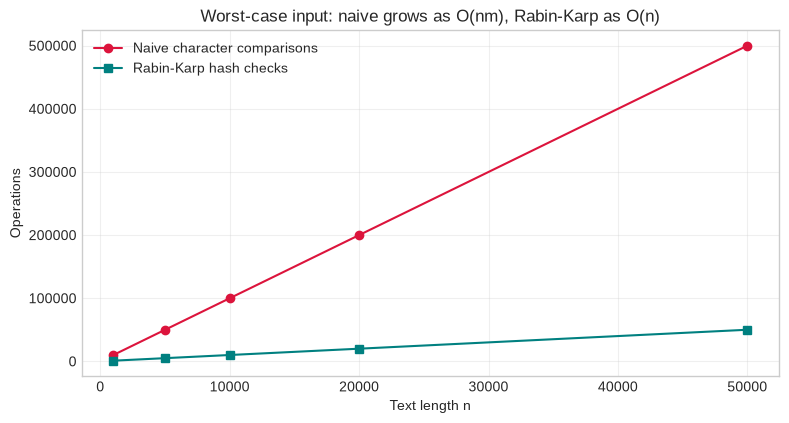

In [8]:
# Compare the character-level work on the repetitive (worst-case) input.
worst_case = benchmark[benchmark["input"] == "repetitive"]

plt.figure(figsize=(9, 4.5))
plt.plot(
    worst_case["n"],
    worst_case["naive character comparisons"],
    "o-",
    label="Naive character comparisons",
    color="crimson",
)
plt.plot(
    worst_case["n"],
    worst_case["RK hash checks"],
    "s-",
    label="Rabin-Karp hash checks",
    color="teal",
)
plt.xlabel("Text length n")
plt.ylabel("Operations")
plt.title("Worst-case input: naive grows as O(nm), Rabin-Karp as O(n)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

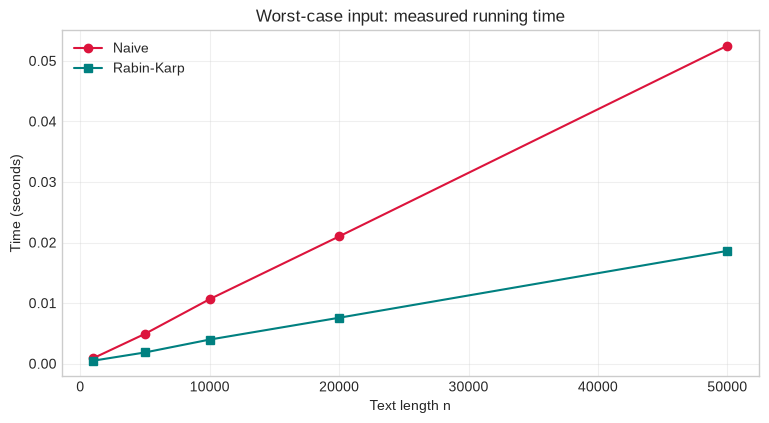

In [9]:
# Wall-clock times on the same input. For small n, Python's per-window hash
# arithmetic can make Rabin-Karp slower even though it performs fewer character
# comparisons; at larger n the asymptotic advantage becomes visible.
plt.figure(figsize=(9, 4.5))
plt.plot(
    worst_case["n"],
    worst_case["naive time (s)"],
    "o-",
    label="Naive",
    color="crimson",
)
plt.plot(
    worst_case["n"],
    worst_case["RK time (s)"],
    "s-",
    label="Rabin-Karp",
    color="teal",
)
plt.xlabel("Text length n")
plt.ylabel("Time (seconds)")
plt.title("Worst-case input: measured running time")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

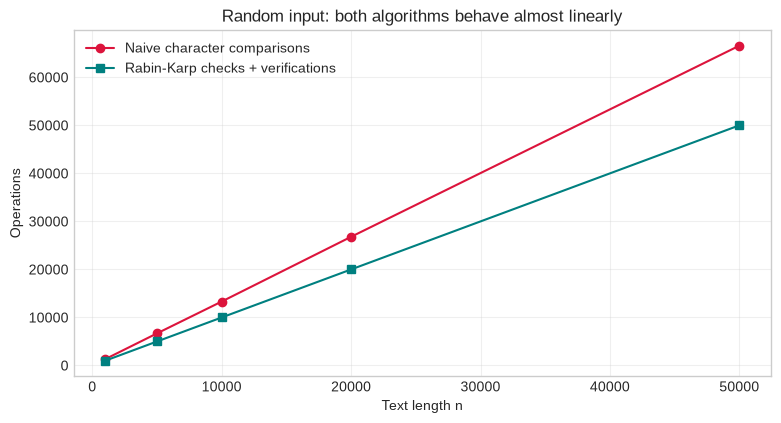

In [10]:
# Average-case comparison on random DNA text.
random_case = benchmark[benchmark["input"] == "random"]

plt.figure(figsize=(9, 4.5))
plt.plot(
    random_case["n"],
    random_case["naive character comparisons"],
    "o-",
    label="Naive character comparisons",
    color="crimson",
)
plt.plot(
    random_case["n"],
    random_case["RK hash checks"] + random_case["RK character verifications"],
    "s-",
    label="Rabin-Karp checks + verifications",
    color="teal",
)
plt.xlabel("Text length n")
plt.ylabel("Operations")
plt.title("Random input: both algorithms behave almost linearly")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - DAA Practical 6 (String Matching)")
print("=" * 78)
print(
    "The naive algorithm compares characters window by window. Rabin-Karp\n"
    "compares a rolling hash first and verifies characters only when the hash\n"
    "matches. The output below separates match correctness from operation\n"
    "counts and wall-clock time."
)

classic_text = "AABAACAADAABAABA"
classic_pattern = "AABA"
classic_naive_matches, classic_naive_comparisons = naive_search(classic_text, classic_pattern)
classic_rk_matches, classic_rk_hashes, classic_rk_verifications = rabin_karp(
    classic_text, classic_pattern
)
print("\n1. CLASSIC EXAMPLE")
print("-" * 78)
print(f"Text              : {classic_text}")
print(f"Pattern           : {classic_pattern}")
print(f"Naive matches     : {classic_naive_matches}")
print(f"Rabin-Karp matches: {classic_rk_matches}")
print(f"Naive comparisons : {classic_naive_comparisons}")
print(f"RK hash checks    : {classic_rk_hashes}")
print(f"RK verifications  : {classic_rk_verifications}")
print(f"Both algorithms agree: {classic_naive_matches == classic_rk_matches}")
print("The three matches are at positions 0, 9 and 12. Rabin-Karp performs one")
print("hash check per window, then verifies the matching windows character by")
print("character. A hash match is only a candidate; verification is essential.")

print("\n2. WORST-CASE INPUT (TEXT ALL 'A', PATTERN A...AB)")
print("-" * 78)
print(f"Text length          : {len(repetitive_text):,}")
print(f"Pattern length       : {len(repetitive_pattern)}")
print(f"Naive matches        : {naive_matches}")
print(f"RK matches           : {rk_matches}")
print(f"Naive comparisons    : {naive_comparisons:,}")
print(
    "Theoretical maximum  :",
    f"{(len(repetitive_text) - len(repetitive_pattern) + 1) * len(repetitive_pattern):,}",
)
print(f"RK hash checks       : {rk_hashes:,}")
print(f"RK verifications     : {rk_verifications:,}")
print("At every alignment the pattern matches for nine characters and fails on")
print("the final B. Naive search therefore does about m comparisons per window.")
print("The pattern hash never equals the all-A window hashes, so Rabin-Karp")
print("rejects every window with one integer comparison and needs zero")
print("character verifications. This is the O(nm) vs O(n) contrast in action.")

print("\n3. BENCHMARK ACROSS INPUT SIZES")
print("-" * 78)
for _, row in benchmark.iterrows():
    print(
        f"  {row['input']:10s} n={int(row['n']):6,d}: "
        f"naive={int(row['naive character comparisons']):8,d} char comps "
        f"({float(row['naive time (s)']):.6f} s)"
    )
    print(
        f"  {'':10s}            RK={int(row['RK hash checks']):8,d} hash checks "
        f"+ {int(row['RK character verifications']):5,d} verifications "
        f"({float(row['RK time (s)']):.6f} s)"
    )

largest_repetitive = benchmark[
    (benchmark["input"] == "repetitive") & (benchmark["n"] == benchmark["n"].max())
].iloc[0]
largest_random = benchmark[
    (benchmark["input"] == "random") & (benchmark["n"] == benchmark["n"].max())
].iloc[0]
repetitive_ratio = (
    largest_repetitive["naive character comparisons"]
    / max(largest_repetitive["RK hash checks"], 1)
)
print(f"\nAt n={int(largest_repetitive['n']):,} on repetitive input:")
print(
    f"  naive/RK operation ratio = {repetitive_ratio:.2f}x "
    "(naive character comparisons divided by RK hash checks)"
)
print(
    "  measured time: naive "
    f"{float(largest_repetitive['naive time (s)']):.6f} s, RK "
    f"{float(largest_repetitive['RK time (s)']):.6f} s"
)
print("The operation ratio grows with the pattern length. Rabin-Karp is also")
print("faster in wall-clock time on this repetitive case. On random or short")
print("inputs, however, Python's per-window modular arithmetic can make its")
print("constant factor larger than the simple character loop; the asymptotic")
print("advantage matters most when n and m are large.")

print(f"\nAt n={int(largest_random['n']):,} on random DNA input:")
print(
    f"  naive character comparisons: {int(largest_random['naive character comparisons']):,}"
)
print(
    f"  RK hash checks + verifications: "
    f"{int(largest_random['RK hash checks']) + int(largest_random['RK character verifications']):,}"
)
print("Random text usually mismatches at the first character, so the naive")
print("algorithm is already close to linear. Rabin-Karp is also linear, but its")
print("constant factor is larger here. The naive algorithm is competitive on")
print("random data and has almost no preprocessing overhead.")

print("\n4. WHEN DOES EACH ALGORITHM WIN?")
print("-" * 78)
print("Naive       : simple, O(1) extra space, best when mismatches occur early.")
print("Rabin-Karp  : better on repetitive/adversarial text and for multiple")
print("              patterns sharing one hash; expected O(n+m).")
print("Both have an O(nm) worst case. In Rabin-Karp the worst case needs many")
print("hash collisions, because every candidate window is verified.")
print("A large prime modulus such as 1,000,000,007 greatly reduces collisions.")

print("\n5. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Naive       : preprocessing O(1), matching O(nm) worst, O(n) best, space O(1)")
print("Rabin-Karp  : preprocessing O(m), expected O(n+m), O(nm) with collisions, space O(1)")
print("The experiments match the theory: repetitive input exposes the quadratic")
print("character work of naive matching, while random input hides it.")

DETAILED OUTPUT EXPLANATION - DAA Practical 6 (String Matching)
The naive algorithm compares characters window by window. Rabin-Karp
compares a rolling hash first and verifies characters only when the hash
matches. The output below separates match correctness from operation
counts and wall-clock time.

1. CLASSIC EXAMPLE
------------------------------------------------------------------------------
Text              : AABAACAADAABAABA
Pattern           : AABA
Naive matches     : [0, 9, 12]
Rabin-Karp matches: [0, 9, 12]
Naive comparisons : 30
RK hash checks    : 13
RK verifications  : 12
Both algorithms agree: True
The three matches are at positions 0, 9 and 12. Rabin-Karp performs one
hash check per window, then verifies the matching windows character by
character. A hash match is only a candidate; verification is essential.

2. WORST-CASE INPUT (TEXT ALL 'A', PATTERN A...AB)
------------------------------------------------------------------------------
Text length          : 20,000
P

### Observations

1. On the classic example, both algorithms report the same three matches.
2. On the repetitive worst-case input, the naive algorithm performs
   $(n-m+1)(m-1)$ character comparisons — quadratic when $m$ grows with $n$.
   Rabin-Karp performs one hash comparison per window and, in this example,
   no character verifications.
3. On random text, the naive algorithm usually fails at the first or second
   character, so its average work is close to linear. Rabin-Karp also behaves
   linearly, but its constant factor can be larger in Python because each
   window requires modular arithmetic.
4. A hash match is not proof of a match. Rabin-Karp always verifies candidate
   windows. If every window collides, the verification step can make the
   worst case $O(nm)$.
5. The choice of modulus matters. A large prime (here $10^9+7$) reduces the
   collision probability. A small modulus such as 101 would cause many false
   candidates.

### Complexity analysis

| Algorithm | Preprocessing | Matching | Worst case | Extra space |
|---|---|---|---|---|
| Naive | $O(1)$ | $O(nm)$ worst, $O(n)$ best | $O(nm)$ | $O(1)$ |
| Rabin-Karp | $O(m)$ | $O(n+m)$ expected | $O(nm)$ with collisions | $O(1)$ |

## 5. Conclusion

We implemented the naive and Rabin-Karp string-matching algorithms and
verified that they return identical match positions on a range of inputs. The
experiments show the practical difference between comparing every character
of every window and comparing a single rolling hash per window. Rabin-Karp is
much better on repetitive worst-case data, while the naive algorithm is
competitive on random text and has a smaller constant factor. The project also
demonstrates why hash verification is essential for correctness.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is the worst-case time of naive string matching? | $O(nm)$. |
| What is the expected time of Rabin-Karp? | $O(n+m)$. |
| What is a rolling hash? | A hash of a sliding window that is updated in $O(1)$ by removing the outgoing character and adding the incoming one. |
| Why must Rabin-Karp verify a hash match? | Different strings can have the same hash (a collision). |
| What happens if the modulus is too small? | Many collisions, so many verifications and performance approaches $O(nm)$. |
| Is Rabin-Karp in-place? | Yes; it uses $O(1)$ extra space apart from the output. |
| What is a good modulus? | A large prime, e.g. $10^9+7$ or $10^9+9$. |
| Where is Rabin-Karp used? | Plagiarism detection, DNA matching, multiple-pattern search and content fingerprinting. |
| Which algorithm is better for random text? | Both are near-linear; the naive version may have a smaller constant factor. |
| What is the difference between exact and approximate string matching? | Exact matching requires every character to agree; approximate matching allows edits (insert/delete/substitute). |